# Exploratory Data Analysis (EDA)

Research question: **Which factors are associated with the severity of road accidents with personal injury in Switzerland, in particular urban/rural and day/night?**

- **H1:** In rural areas the share of severe or fatal outcomes is higher than in urban areas.
- **H2:** During night hours the share of severe or fatal outcomes is higher than during the day.

Target variable `severe` = 1 (seriously injured / killed), 0 (slightly injured). `accident_type` and `road_type` are descriptive control variables only.

Input: `data/processed/accidents_clean.parquet` produced by `01_data.ipynb`. **No re-cleaning in this notebook.** All numbers in the text are taken from the code output above them; they may shift slightly once the BFS join in `01_data.ipynb` is corrected.

## Libraries and settings

In [1]:
# Libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patheffects as pe
import seaborn as sns
import geopandas as gpd
from scipy.stats import chi2, chi2_contingency, norm

# Ignore warnings
import warnings
warnings.filterwarnings("ignore")

# Fixed seed (no random steps here, set for consistency across notebooks)
np.random.seed(42)

# Plot settings
pd.set_option("display.max_columns", 50)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
COLOR_MAIN = "#2a78d6"    # blue
COLOR_NIGHT = "#eb6834"   # orange
COLOR_GREY = "#c3c2b7"    # municipalities/cantons below the minimum case number

# Show current working directory
print(os.getcwd())

C:\Users\ericb\Documents\swiss-road-accident-severity\swiss-road-accident-severity\nootebooks


## Import the cleaned accident data

In [2]:
df = pd.read_parquet("../data/processed/accidents_clean.parquet")

print("Rows and columns:", df.shape)
print(df.dtypes)
df.head()

Rows and columns: (89193, 19)
accident_id                        str
year                             int64
AccidentMonth                    int64
AccidentWeekDay                    str
hour                             int64
severity                           str
accident_type                      str
road_type                          str
municipality_code                Int64
CantonCode                         str
AccidentLocation_CHLV95_E        int64
AccidentLocation_CHLV95_N        int64
AccidentInvolvingPedestrian       bool
AccidentInvolvingBicycle          bool
AccidentInvolvingMotorcycle       bool
urban_rural                    float64
severe                           int64
night                            Int64
area_type                          str
dtype: object


,accident_id,year,AccidentMonth,AccidentWeekDay,hour,severity,accident_type,road_type,municipality_code,CantonCode,AccidentLocation_CHLV95_E,AccidentLocation_CHLV95_N,AccidentInvolvingPedestrian,AccidentInvolvingBicycle,AccidentInvolvingMotorcycle,urban_rural,severe,night,area_type
0,00060284C00AC34F87BBABA6C3809CCD,2024,11,aw404,17,as3,at3,rt433,96,ZH,2677917,1255472,False,True,False,1.0,0,0,Urban
1,00075447B4B5C04CAE5F154F8D369CAC,2024,8,aw403,12,as2,at1,rt432,5451,VD,2571182,1190763,False,False,True,3.0,1,0,Rural
2,00098A69568701B0E0630AB38B02C0F4,2023,4,aw407,22,as2,at2,rt430,4107,AG,2660049,1255757,False,False,True,2.0,1,1,Intermediate
3,00098A695D7B01B0E0630AB38B02C0F4,2023,6,aw405,17,as3,at5,rt432,261,ZH,2683261,1252404,False,False,False,1.0,0,0,Urban
4,00098A695E4501B0E0630AB38B02C0F4,2023,6,aw405,8,as2,at3,rt432,4048,AG,2669529,1255399,False,True,False,1.0,1,0,Urban


### Helper functions

Used for H1 and H2 so that both hypotheses are analysed in exactly the same way.

- `severe_share_table`: cases, severe cases and share severe per group.
- `chi2_test`: χ² test of independence with `scipy.stats.chi2_contingency`, critical value at α = 0.05 and check of the expected frequencies (rule of thumb: all expected frequencies ≥ 5).
- `cramers_v`: effect size $V = \sqrt{\chi^2 / (n \cdot (\min(r, c) - 1))}$ (computed from the χ² without continuity correction).
- `risk_comparison`: risk difference (percentage points) and risk ratio with 95 % confidence intervals (Wald CI for the difference, log-scale CI for the ratio).

In [3]:
def severe_share_table(data, group_col, order=None):
    """Cases, severe cases and share severe (in %) per group."""
    tab = (data.groupby(group_col)["severe"]
               .agg(cases="size", severe_cases="sum"))
    tab["share_severe_pct"] = (tab["severe_cases"] / tab["cases"] * 100).round(2)
    if order is not None:
        tab = tab.loc[order]
    return tab


def chi2_test(crosstab, alpha=0.05):
    """Chi-square test of independence incl. critical value and expected-frequency check."""
    stat, p, dof, expected = chi2_contingency(crosstab)  # Yates correction applies only to 2x2
    crit = chi2.ppf(1 - alpha, dof)
    expected = pd.DataFrame(expected, index=crosstab.index, columns=crosstab.columns)
    print(f"n = {int(crosstab.values.sum()):,}")
    print(f"Chi-square statistic: {stat:.2f}")
    print(f"Degrees of freedom:   {dof}")
    print(f"Critical value (alpha = {alpha}): {crit:.2f}")
    print(f"p-value: {p:.3g}")
    print(f"Smallest expected frequency: {expected.values.min():.1f} "
          f"(all >= 5: {bool((expected.values >= 5).all())})")
    print("\nExpected frequencies under independence:")
    display(expected.round(1))
    return {"chi2": stat, "dof": dof, "p": p, "critical_value": crit, "expected": expected}


def cramers_v(crosstab):
    """Cramer's V based on the uncorrected chi-square statistic."""
    stat = chi2_contingency(crosstab, correction=False)[0]
    n = crosstab.values.sum()
    k = min(crosstab.shape) - 1
    return np.sqrt(stat / (n * k))


def risk_comparison(data, group_col, exposed, reference, alpha=0.05):
    """Risk difference (pp) and risk ratio of severe outcome, exposed vs. reference, with CIs."""
    z = norm.ppf(1 - alpha / 2)
    a = data.loc[data[group_col] == exposed, "severe"]
    b = data.loc[data[group_col] == reference, "severe"]
    n1, x1, n0, x0 = len(a), a.sum(), len(b), b.sum()
    p1, p0 = x1 / n1, x0 / n0

    rd = p1 - p0
    se_rd = np.sqrt(p1 * (1 - p1) / n1 + p0 * (1 - p0) / n0)

    rr = p1 / p0
    se_log_rr = np.sqrt(1 / x1 - 1 / n1 + 1 / x0 - 1 / n0)

    return pd.DataFrame({
        "measure": [f"Risk difference {exposed} - {reference} (pp)",
                    f"Risk ratio {exposed} / {reference}"],
        "estimate": [rd * 100, rr],
        "ci_lower_95": [(rd - z * se_rd) * 100, np.exp(np.log(rr) - z * se_log_rr)],
        "ci_upper_95": [(rd + z * se_rd) * 100, np.exp(np.log(rr) + z * se_log_rr)],
    }).round(3)


def bar_share(tab, title, xlabel, color=COLOR_MAIN, ax=None, show_n=True):
    """Bar chart of the share severe per group, annotated with share and n."""
    if ax is None:
        _, ax = plt.subplots(figsize=(7, 4))
    labels = [str(i) for i in tab.index]
    bars = ax.bar(labels, tab["share_severe_pct"], color=color, width=0.6)
    for bar, (_, row) in zip(bars, tab.iterrows()):
        label = f"{row['share_severe_pct']:.1f} %"
        if show_n:
            label += f"\n(n = {int(row['cases']):,})"
        ax.annotate(label,
                    (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                    ha="center", va="bottom", fontsize=9, xytext=(0, 2),
                    textcoords="offset points")
    ax.set_ylim(0, tab["share_severe_pct"].max() * 1.25)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Share severe / fatal (%)")
    ax.set_title(title)
    ax.grid(axis="x", visible=False)
    return ax

## 1. Overview of the data (non-graphical)

### Case numbers, years and target variable

In [4]:
print("Number of accidents:", f"{len(df):,}")
print("Unique accident IDs:", f"{df['accident_id'].nunique():,}")
print("Years:", df["year"].min(), "-", df["year"].max())
print("Municipalities:", df["municipality_code"].nunique(), "| Cantons:", df["CantonCode"].nunique())

print("\nOriginal severity categories (as1/as2 -> severe = 1, as3 -> severe = 0, see 01_data):")
print(pd.crosstab(df["severity"], df["severe"], margins=True))

print("\nShare severe / fatal overall:", f"{df['severe'].mean() * 100:.2f} %")

Number of accidents: 89,193
Unique accident IDs: 89,193
Years: 2021 - 2025
Municipalities: 2030 | Cantons: 26

Original severity categories (as1/as2 -> severe = 1, as3 -> severe = 0, see 01_data):
severe        0      1    All
severity                     
as1           0   1091   1091
as2           0  18599  18599
as3       69503      0  69503
All       69503  19690  89193

Share severe / fatal overall: 22.08 %


In [5]:
by_year = severe_share_table(df, "year")
by_year

,cases,severe_cases,share_severe_pct
year,,,
2021,17371,3893,22.41
2022,18325,3978,21.71
2023,18185,4094,22.51
2024,17362,3811,21.95
2025,17950,3914,21.81


**Interpretation:** One row corresponds to one accident (accident IDs are unique). Severe or fatal outcomes are a clear minority of all injury accidents, and fatal accidents (`as1`) make up only a small part of the severe group, so `severe` mainly reflects seriously injured persons. The yearly shares are very close to each other, so pooling 2021-2025 is reasonable for the EDA (whether `year` enters the model as a control is still an open team decision). The imbalance between the classes matters for the model evaluation in `03_model.ipynb`: a model that always predicts 'not severe' already reaches a high accuracy.

### Missing values and value ranges

In [6]:
missing = pd.DataFrame({
    "missing": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
})
display(missing)

display(df[["year", "AccidentMonth", "hour"]].describe().round(2))

,missing,missing_pct
accident_id,0,0.0
year,0,0.0
AccidentMonth,0,0.0
AccidentWeekDay,0,0.0
hour,0,0.0
severity,0,0.0
accident_type,0,0.0
road_type,0,0.0
municipality_code,0,0.0
CantonCode,0,0.0


,year,AccidentMonth,hour
count,89193.00,89193.00,89193.00
mean,2023.00,6.76,13.36
std,1.41,3.13,5.09
min,2021.00,1.00,0.00
25%,2022.00,4.00,10.00
50%,2023.00,7.00,14.00
75%,2024.00,9.00,17.00
max,2025.00,12.00,23.00


In [7]:
# Distribution of the key categorical variables
for col in ["area_type", "night", "accident_type", "road_type"]:
    counts = df[col].value_counts().sort_index()
    print(pd.DataFrame({"n": counts, "pct": (counts / len(df) * 100).round(2)}), "\n")

                  n    pct
area_type                 
Intermediate  17463  19.58
Rural         13394  15.02
Urban         58336  65.40 

           n    pct
night              
0      80345  90.08
1       8848   9.92 



                   n    pct
accident_type              
at0            32544  36.49
at00            1010   1.13
at1             4365   4.89
at2            15059  16.88
at3             6929   7.77
at4            10415  11.68
at5             4273   4.79
at6             3574   4.01
at7             1122   1.26
at8             9518  10.67
at9              384   0.43 

               n    pct
road_type              
rt430       7426   8.33
rt431        700   0.78
rt432      42971  48.18
rt433      34321  38.48
rt434         36   0.04
rt439       3739   4.19 



**Interpretation:** The parquet file has no missing values. This is because `01_data.ipynb` already removed the accidents without a BFS match (see the loss table there), so the EDA works only with matched accidents. Night accidents (by clock-time definition) are a small group compared with day accidents. Some categories are very small (e.g. `rt434`, `at9`, `at00`): their shares are unstable and they may cause problems as one-hot dummies in the model. `urban_rural` (numeric code) and `area_type` (text) contain the same information.

## 2. H1: Urban / rural (`area_type`)

`area_type` is the BFS urban/rural typology (Urban, Intermediate, Rural) joined in `01_data.ipynb`. The main test uses all three categories (3x2 table). Because H1 compares rural with urban, Rural vs. Urban is additionally tested as a 2x2 table (intermediate municipalities excluded there).

In [8]:
AREA_ORDER = ["Urban", "Intermediate", "Rural"]

h1_tab = severe_share_table(df, "area_type", order=AREA_ORDER)
display(h1_tab)

h1_ct = pd.crosstab(df["area_type"], df["severe"]).loc[AREA_ORDER]
h1_ct.columns = ["not_severe (0)", "severe (1)"]
display(h1_ct)

,cases,severe_cases,share_severe_pct
area_type,,,
Urban,58336,11607,19.90
Intermediate,17463,4278,24.50
Rural,13394,3805,28.41


,not_severe (0),severe (1)
area_type,,
Urban,46729,11607
Intermediate,13185,4278
Rural,9589,3805


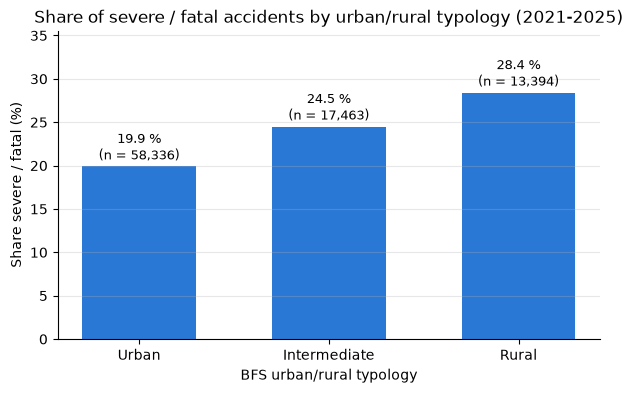

In [9]:
bar_share(h1_tab, "Share of severe / fatal accidents by urban/rural typology (2021-2025)",
          "BFS urban/rural typology")
plt.show()

**Interpretation:** The share of severe/fatal accidents increases from urban over intermediate to rural municipalities, which is the direction expected by H1. What we cannot say: that driving in rural areas is more dangerous per kilometre or per trip. The share only describes how severe an accident is *given that* an injury accident happened, and rural and urban accidents differ in type and circumstances (see section 6).

### Chi-square test 3x2 (Urban / Intermediate / Rural x severe)

- H0: Severity is independent of the urban/rural typology.
- H1: Severity depends on the urban/rural typology.

In [10]:
h1_res = chi2_test(h1_ct)
print(f"\nCramer's V: {cramers_v(h1_ct):.3f}")

n = 89,193
Chi-square statistic: 532.77
Degrees of freedom:   2
Critical value (alpha = 0.05): 5.99
p-value: 2.04e-116
Smallest expected frequency: 2956.8 (all >= 5: True)

Expected frequencies under independence:


,not_severe (0),severe (1)
area_type,,
Urban,45457.9,12878.1
Intermediate,13607.9,3855.1
Rural,10437.2,2956.8



Cramer's V: 0.077


### Chi-square test 2x2 (Rural vs. Urban) and effect sizes

In [11]:
df_ru = df[df["area_type"].isin(["Urban", "Rural"])]
h1_ct2 = pd.crosstab(df_ru["area_type"], df_ru["severe"]).loc[["Urban", "Rural"]]
h1_ct2.columns = ["not_severe (0)", "severe (1)"]
display(h1_ct2)

h1_res2 = chi2_test(h1_ct2)
print(f"\nCramer's V: {cramers_v(h1_ct2):.3f}")

display(risk_comparison(df, "area_type", exposed="Rural", reference="Urban"))
display(risk_comparison(df, "area_type", exposed="Intermediate", reference="Urban"))

,not_severe (0),severe (1)
area_type,,
Urban,46729,11607
Rural,9589,3805


n = 71,730
Chi-square statistic: 467.28
Degrees of freedom:   1
Critical value (alpha = 0.05): 3.84
p-value: 1.25e-103
Smallest expected frequency: 2877.9 (all >= 5: True)

Expected frequencies under independence:


,not_severe (0),severe (1)
area_type,,
Urban,45801.9,12534.1
Rural,10516.1,2877.9



Cramer's V: 0.081


,measure,estimate,ci_lower_95,ci_upper_95
0,Risk difference Rural - Urban (pp),8.511,7.682,9.341
1,Risk ratio Rural / Urban,1.428,1.384,1.473


,measure,estimate,ci_lower_95,ci_upper_95
0,Risk difference Intermediate - Urban (pp),4.601,3.885,5.316
1,Risk ratio Intermediate / Urban,1.231,1.194,1.270


**Interpretation:** In both tests the χ² statistic is far above the critical value and the p-value is practically zero, so H0 (independence) is rejected for the 3x2 and the 2x2 table. All expected frequencies are far above 5, so the χ² approximation is valid. Cramér's V is small, which is typical for a binary outcome and does not mean that the difference is irrelevant: the risk difference and the risk ratio show that the share of severe accidents is clearly higher in rural than in urban municipalities, and both confidence intervals are far away from 0 (difference) and 1 (ratio). Intermediate municipalities lie in between. The result supports H1 descriptively. It is an association, not a causal effect, and it is not yet adjusted for accident type or road type.

## 3. H2: Day / night (`night`)

`night` = 1 for accident hours 22:00-05:59 (definition from `01_data.ipynb`), otherwise 0. A seasonal darkness definition (month x hour) is not implemented yet; the heatmap in section 5 gives a first descriptive look.

In [12]:
df["day_night"] = df["night"].map({0: "Day (06-21h)", 1: "Night (22-05h)"})
DN_ORDER = ["Day (06-21h)", "Night (22-05h)"]

h2_tab = severe_share_table(df, "day_night", order=DN_ORDER)
display(h2_tab)

h2_ct = pd.crosstab(df["day_night"], df["severe"]).loc[DN_ORDER]
h2_ct.columns = ["not_severe (0)", "severe (1)"]
display(h2_ct)

,cases,severe_cases,share_severe_pct
day_night,,,
Day (06-21h),80345,17506,21.79
Night (22-05h),8848,2184,24.68


,not_severe (0),severe (1)
day_night,,
Day (06-21h),62839,17506
Night (22-05h),6664,2184


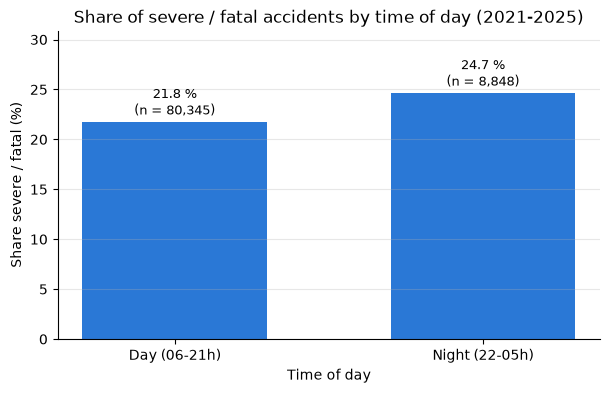

In [13]:
bar_share(h2_tab, "Share of severe / fatal accidents by time of day (2021-2025)",
          "Time of day")
plt.show()

**Interpretation:** At night (22:00-05:59) the share of severe/fatal accidents is higher than during the day, which is the direction expected by H2. The difference is visibly smaller than between urban and rural. Night accidents are a much smaller group, so their share is estimated less precisely.

### Chi-square test 2x2 (night x severe) and effect sizes

- H0: Severity is independent of day/night.
- H1: Severity depends on day/night.

In [14]:
h2_res = chi2_test(h2_ct)
print(f"\nCramer's V: {cramers_v(h2_ct):.3f}")

display(risk_comparison(df, "day_night", exposed="Night (22-05h)", reference="Day (06-21h)"))

n = 89,193
Chi-square statistic: 38.66
Degrees of freedom:   1
Critical value (alpha = 0.05): 3.84
p-value: 5.04e-10
Smallest expected frequency: 1953.3 (all >= 5: True)

Expected frequencies under independence:


,not_severe (0),severe (1)
day_night,,
Day (06-21h),62608.3,17736.7
Night (22-05h),6894.7,1953.3



Cramer's V: 0.021


,measure,estimate,ci_lower_95,ci_upper_95
0,Risk difference Night (22-05h) - Day (06-21h) ...,2.895,1.952,3.838
1,Risk ratio Night (22-05h) / Day (06-21h),1.133,1.090,1.178


**Interpretation:** The χ² test rejects independence (p far below 0.05, all expected frequencies far above 5). Cramér's V, however, is very small, and the risk difference is only a few percentage points (CI excludes 0, risk ratio CI excludes 1). With almost 90,000 accidents even small differences become significant, so H2 is supported in direction but the bivariate effect is weak. The night definition is based on clock time and not on actual darkness.

## 4. Urban/rural x day/night

Share of severe accidents in all six combinations. This is descriptive only; whether the night effect differs between urban and rural areas has to be tested in the model (`rural x night` interaction, `03_model.ipynb`).

In [15]:
inter = (df.groupby(["area_type", "day_night"])["severe"]
           .agg(cases="size", severe_cases="sum"))
inter["share_severe_pct"] = (inter["severe_cases"] / inter["cases"] * 100).round(2)
display(inter.loc[AREA_ORDER])

cases  severe_cases  share_severe_pct
area_type    day_night                                            
Urban        Day (06-21h)    52588         10235             19.46
             Night (22-05h)   5748          1372             23.87
Intermediate Day (06-21h)    15739          3828             24.32
             Night (22-05h)   1724           450             26.10
Rural        Day (06-21h)    12018          3443             28.65
             Night (22-05h)   1376           362             26.31

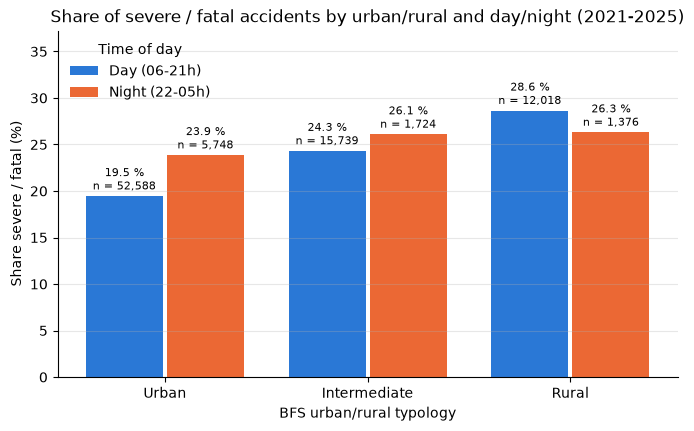

In [16]:
fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(AREA_ORDER))
width = 0.38
for i, (dn, color) in enumerate(zip(DN_ORDER, [COLOR_MAIN, COLOR_NIGHT])):
    sub = inter.xs(dn, level="day_night").loc[AREA_ORDER]
    bars = ax.bar(x + (i - 0.5) * (width + 0.02), sub["share_severe_pct"], width,
                  color=color, label=dn)
    for bar, (_, row) in zip(bars, sub.iterrows()):
        ax.annotate(f"{row['share_severe_pct']:.1f} %\nn = {int(row['cases']):,}",
                    (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                    ha="center", va="bottom", fontsize=8, xytext=(0, 2),
                    textcoords="offset points")
ax.set_xticks(x)
ax.set_xticklabels(AREA_ORDER)
ax.set_ylim(0, inter["share_severe_pct"].max() * 1.3)
ax.set_xlabel("BFS urban/rural typology")
ax.set_ylabel("Share severe / fatal (%)")
ax.set_title("Share of severe / fatal accidents by urban/rural and day/night (2021-2025)")
ax.legend(title="Time of day", frameon=False)
ax.grid(axis="x", visible=False)
plt.show()

**Interpretation:** The night effect is not the same everywhere: in urban municipalities the share at night is clearly higher than during the day, in intermediate municipalities the difference is smaller, and in rural municipalities the night share is not higher than the day share in the current output (point estimate even lower, but based on a small night group). At the same time, the urban/rural gap is smaller at night than during the day. This suggests an interaction between area type and night. Whether it is statistically significant and survives the control variables must be tested in `03_model.ipynb` (`rural x night`). From this plot alone we cannot say that night 'does not matter' in rural areas.

## 5. Time patterns

Number of accidents and share of severe accidents per hour of the day. Shown in two separate panels with a shared x-axis (no dual y-axis). The night window 22:00-05:59 is shaded. The error bars are 95 % Wald confidence intervals of the share.

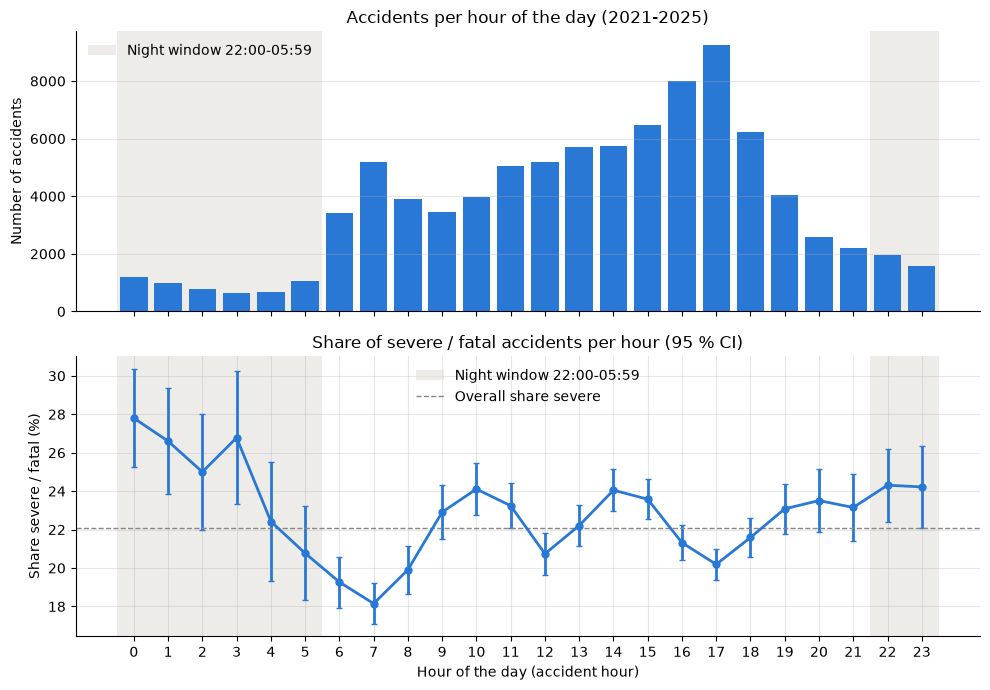

hour,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
cases,1187.00,985.00,780.00,631.00,687.00,1059.00,3409.00,5178.00,3897.00,3439.00,3961.00,5064.00,5203.00,5696.00,5738.00,6463.00,7989.00,9263.00,6226.00,4047.00,2578.00,2194.00,1954.00,1565.00
severe_cases,330.00,262.00,195.00,169.00,154.00,220.00,657.00,940.00,776.00,788.00,955.00,1177.00,1079.00,1265.00,1380.00,1524.00,1703.00,1870.00,1344.00,934.00,606.00,508.00,475.00,379.00
share_severe_pct,27.80,26.60,25.00,26.78,22.42,20.77,19.27,18.15,19.91,22.91,24.11,23.24,20.74,22.21,24.05,23.58,21.32,20.19,21.59,23.08,23.51,23.15,24.31,24.22
ci_half_pct,2.55,2.76,3.04,3.46,3.12,2.44,1.32,1.05,1.25,1.40,1.33,1.16,1.10,1.08,1.11,1.03,0.90,0.82,1.02,1.30,1.64,1.76,1.90,2.12


In [17]:
by_hour = severe_share_table(df, "hour")
by_hour["ci_half_pct"] = 1.96 * np.sqrt(
    (by_hour["share_severe_pct"] / 100) * (1 - by_hour["share_severe_pct"] / 100)
    / by_hour["cases"]) * 100

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
for ax in (ax1, ax2):
    ax.axvspan(-0.5, 5.5, color="#e1e0d9", alpha=0.6, lw=0)
    ax.axvspan(21.5, 23.5, color="#e1e0d9", alpha=0.6, lw=0,
               label="Night window 22:00-05:59")

ax1.bar(by_hour.index, by_hour["cases"], color=COLOR_MAIN, width=0.8)
ax1.set_ylabel("Number of accidents")
ax1.set_title("Accidents per hour of the day (2021-2025)")
ax1.legend(frameon=False, loc="upper left")
ax1.grid(axis="x", visible=False)

ax2.errorbar(by_hour.index, by_hour["share_severe_pct"], yerr=by_hour["ci_half_pct"],
             color=COLOR_MAIN, marker="o", ms=5, lw=2, capsize=2)
ax2.axhline(df["severe"].mean() * 100, color="#898781", ls="--", lw=1,
            label="Overall share severe")
ax2.set_ylabel("Share severe / fatal (%)")
ax2.set_xlabel("Hour of the day (accident hour)")
ax2.set_title("Share of severe / fatal accidents per hour (95 % CI)")
ax2.set_xticks(range(24))
ax2.legend(frameon=False, loc="upper center")
plt.tight_layout()
plt.show()

display(by_hour.round(2).T)

**Interpretation:** Most accidents happen during the day with peaks in the commuting hours, while the night hours have few accidents. The share of severe accidents is highest in the hours after midnight and lowest in the morning rush hour. The confidence intervals are much wider at night because of the small case numbers. Within the fixed night window the hours 4-5 are close to or below the overall average, while the hours 0-3 are clearly above it, so the 22:00-05:59 definition mixes hours with different patterns. A sensitivity analysis with an alternative window or a darkness-based definition is therefore useful. Why the share is higher in some daytime hours (e.g. traffic volume, speed, leisure traffic) cannot be answered with these data.

### Month and weekday

Weekday is only available as ASTRA code (`aw401` ... `aw407`); the mapping of the codes to weekdays is not contained in the parquet file and is therefore **not** guessed here.

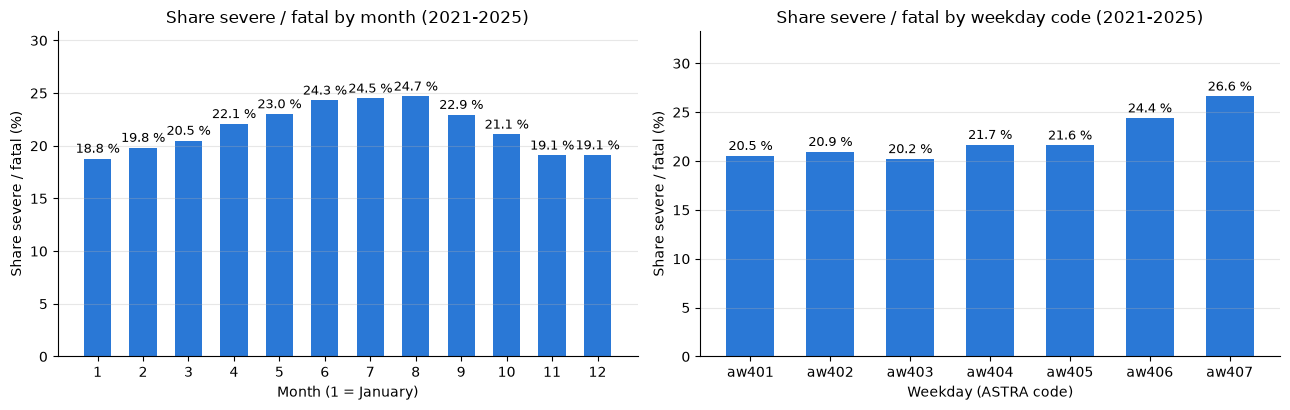

AccidentMonth,1,2,3,4,5,6,7,8,9,10,11,12
cases,5009.00,4753.00,6540.00,6917.00,8679.00,10033.00,8564.0,9016.00,9226.00,7898.00,7052.00,5506.00
severe_cases,941.00,942.00,1340.00,1527.00,1997.00,2439.00,2098.0,2226.00,2117.00,1665.00,1346.00,1052.00
share_severe_pct,18.79,19.82,20.49,22.08,23.01,24.31,24.5,24.69,22.95,21.08,19.09,19.11


AccidentWeekDay,aw401,aw402,aw403,aw404,aw405,aw406,aw407
cases,12437.00,13360.00,13708.00,13577.00,14359.00,12157.00,9595.00
severe_cases,2555.00,2799.00,2772.00,2942.00,3103.00,2965.00,2554.00
share_severe_pct,20.54,20.95,20.22,21.67,21.61,24.39,26.62


In [18]:
by_month = severe_share_table(df, "AccidentMonth")
by_wday = severe_share_table(df, "AccidentWeekDay")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2))
bar_share(by_month, "Share severe / fatal by month (2021-2025)", "Month (1 = January)",
          ax=ax1, show_n=False)
bar_share(by_wday, "Share severe / fatal by weekday code (2021-2025)", "Weekday (ASTRA code)",
          ax=ax2, show_n=False)
plt.tight_layout()
plt.show()

# Case numbers per bar
display(by_month.T)
display(by_wday.T)

### Heatmap month x hour

First descriptive look at seasonal darkness: in winter it is dark earlier in the evening and later in the morning. Cells with fewer than 30 accidents are left empty.

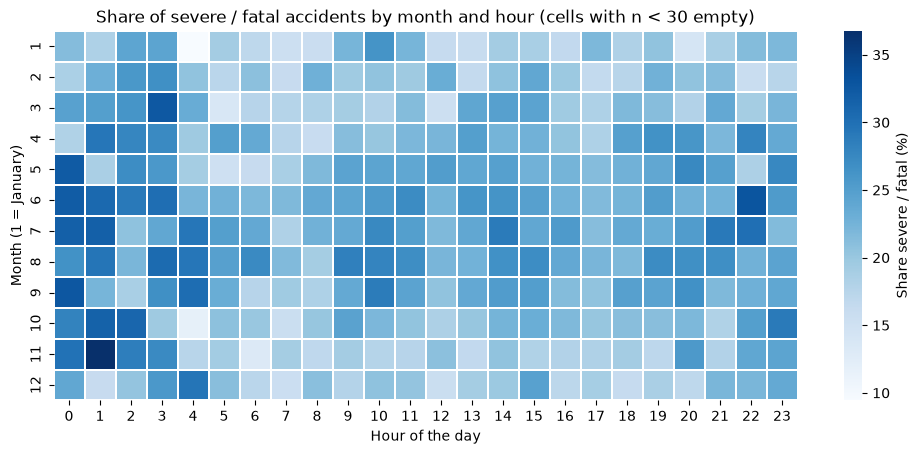

Smallest cell n: 31 | cells below threshold: 0


In [19]:
MIN_N_CELL = 30
mh = df.groupby(["AccidentMonth", "hour"])["severe"].agg(["size", "mean"])
share_mh = (mh["mean"] * 100).unstack("hour")
n_mh = mh["size"].unstack("hour")
share_mh = share_mh.where(n_mh >= MIN_N_CELL)

fig, ax = plt.subplots(figsize=(12, 4.8))
sns.heatmap(share_mh, cmap="Blues", ax=ax, linewidths=0.3, linecolor="white",
            cbar_kws={"label": "Share severe / fatal (%)"})
ax.grid(False)
ax.set_xlabel("Hour of the day")
ax.set_ylabel("Month (1 = January)")
ax.set_title(f"Share of severe / fatal accidents by month and hour (cells with n < {MIN_N_CELL} empty)")
plt.show()

print("Smallest cell n:", int(n_mh.values.min()), "| cells below threshold:", int((n_mh < MIN_N_CELL).values.sum()))

**Interpretation:** The share of severe accidents is higher in the summer months than in winter. If darkness alone drove severity, we would rather expect higher shares in the dark winter months, so other seasonal factors (e.g. more motorcycle and bicycle traffic in summer, see the involvement table below) probably play a role. This is a hypothesis, not tested here. The weekday codes `aw406` and `aw407` show higher shares than the other codes; what weekdays these codes stand for must be confirmed with the ASTRA code list (person A) before interpreting it. The month x hour heatmap is noisy: cells contain only few accidents at night, so no clear darkness pattern can be read from it.

## 6. Control variables: `accident_type` and `road_type`

**Note:** The parquet file only contains the ASTRA codes (e.g. `at0`, `rt432`). The German labels (`AccidentType_de`, `RoadType_de`) exist in the raw data but were not kept in `01_data.ipynb`. The codes are therefore shown as they are; **labels are requested from person A** (no guessing of meanings here).

In [20]:
at_tab = severe_share_table(df, "accident_type").sort_values("share_severe_pct", ascending=False)
rt_tab = severe_share_table(df, "road_type").sort_values("share_severe_pct", ascending=False)
display(at_tab)
display(rt_tab)

,cases,severe_cases,share_severe_pct
accident_type,,,
at9,384,122,31.77
at6,3574,1080,30.22
at0,32544,9209,28.30
at8,9518,2463,25.88
at00,1010,255,25.25
at1,4365,932,21.35
at3,6929,1475,21.29
at5,4273,819,19.17
at4,10415,1692,16.25


,cases,severe_cases,share_severe_pct
road_type,,,
rt439,3739,1003,26.83
rt434,36,9,25.00
rt433,34321,8226,23.97
rt432,42971,9454,22.00
rt431,700,151,21.57
rt430,7426,847,11.41


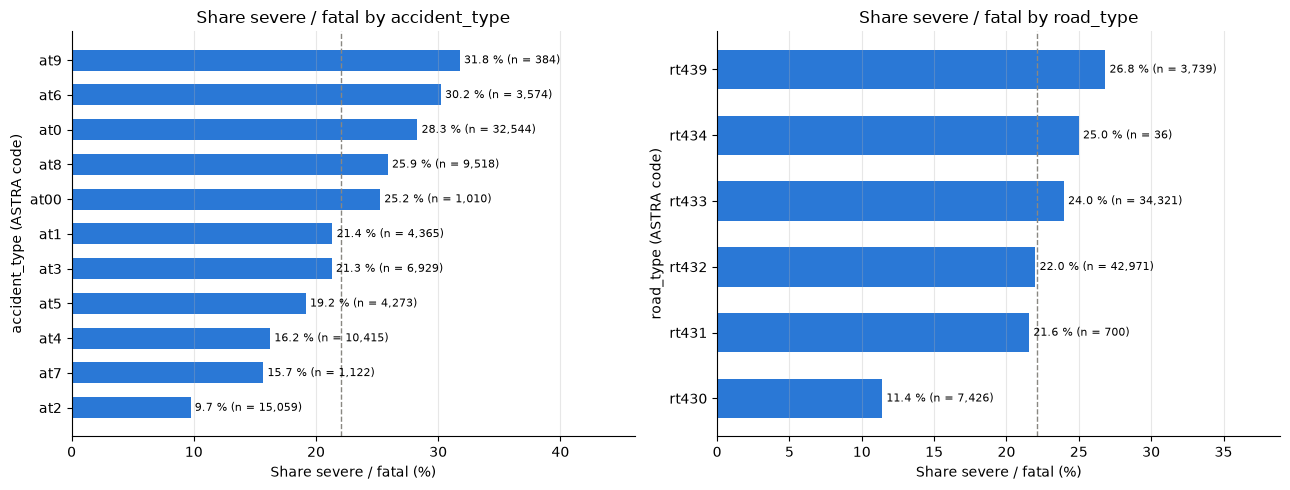

In [21]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
for ax, tab, title in [(ax1, at_tab, "accident_type"), (ax2, rt_tab, "road_type")]:
    tab = tab.sort_values("share_severe_pct")
    bars = ax.barh(tab.index.astype(str), tab["share_severe_pct"], color=COLOR_MAIN, height=0.6)
    for bar, (_, row) in zip(bars, tab.iterrows()):
        ax.annotate(f"{row['share_severe_pct']:.1f} % (n = {int(row['cases']):,})",
                    (bar.get_width(), bar.get_y() + bar.get_height() / 2),
                    va="center", fontsize=8, xytext=(3, 0), textcoords="offset points")
    ax.axvline(df["severe"].mean() * 100, color="#898781", ls="--", lw=1)
    ax.set_xlim(0, tab["share_severe_pct"].max() * 1.45)
    ax.set_xlabel("Share severe / fatal (%)")
    ax.set_ylabel(f"{title} (ASTRA code)")
    ax.set_title(f"Share severe / fatal by {title}")
    ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

**Interpretation:** The share of severe accidents differs much more between accident types than between urban and rural: some codes are far above the overall average, others far below it. For road types, `rt430` has a much lower share than the other types; `rt434` has very few cases, so its share is not reliable. Because the parquet file contains only codes, we cannot yet say which accident or road types these are. **Labels from person A are needed** before these results can be described in the presentation.

### Composition: road type and accident type by urban/rural

If rural and urban accidents happen on different road types or are of different types, part of the urban/rural difference in section 2 may be due to this composition. This is a reason to include the control variables in the model.

In [22]:
print("Road type distribution within each area type (row %):")
display((pd.crosstab(df["area_type"], df["road_type"], normalize="index") * 100).loc[AREA_ORDER].round(1))

print("Accident type distribution within each area type (row %):")
display((pd.crosstab(df["area_type"], df["accident_type"], normalize="index") * 100).loc[AREA_ORDER].round(1))

print("Road type distribution day vs. night (row %):")
display((pd.crosstab(df["day_night"], df["road_type"], normalize="index") * 100).loc[DN_ORDER].round(1))

Road type distribution within each area type (row %):


road_type,rt430,rt431,rt432,rt433,rt434,rt439
area_type,,,,,,
Urban,8.1,0.6,45.8,40.9,0.0,4.5
Intermediate,8.8,1.1,51.5,34.7,0.1,3.9
Rural,8.6,1.4,54.0,32.8,0.0,3.2


Accident type distribution within each area type (row %):


accident_type,at0,at00,at1,at2,at3,at4,at5,at6,at7,at8,at9
area_type,,,,,,,,,,,
Urban,32.4,1.2,5.1,17.7,8.6,12.1,5.5,2.7,1.5,12.9,0.3
Intermediate,41.2,0.9,4.3,16.2,6.3,12.3,3.5,5.5,0.9,8.3,0.7
Rural,48.1,1.0,4.9,14.2,6.0,9.0,3.3,7.9,0.6,4.2,0.9


Road type distribution day vs. night (row %):


road_type,rt430,rt431,rt432,rt433,rt434,rt439
day_night,,,,,,
Day (06-21h),8.2,0.8,48.5,38.3,0.0,4.2
Night (22-05h),9.9,0.7,45.2,40.0,0.1,4.1


**Interpretation:** The composition of accidents differs between area types: in rural municipalities codes `at0` and `at6` (both above-average severity) are much more frequent, while `at2` (lowest severity) and `at8` are more frequent in urban municipalities. Part of the urban/rural difference in section 2 could therefore be due to *which* accidents happen where, which is why `accident_type` must be included as a control in the model. The road type distribution differs less between area types and between day and night.

### Involvement of pedestrians, bicycles and motorcycles

Boolean flags from the ASTRA data (not part of the hypotheses, descriptive context only).

In [23]:
inv_cols = ["AccidentInvolvingPedestrian", "AccidentInvolvingBicycle", "AccidentInvolvingMotorcycle"]
rows = []
for col in inv_cols:
    for val in [False, True]:
        sub = df.loc[df[col] == val, "severe"]
        rows.append({"variable": col, "involved": val, "cases": len(sub),
                     "share_severe_pct": round(sub.mean() * 100, 2)})
pd.DataFrame(rows).set_index(["variable", "involved"])

cases  share_severe_pct
variable                    involved                         
AccidentInvolvingPedestrian False     79498             21.57
                            True       9695             26.19
AccidentInvolvingBicycle    False     64148             20.12
                            True      25045             27.09
AccidentInvolvingMotorcycle False     70473             19.75
                            True      18720             30.82

**Interpretation:** Accidents involving motorcycles, bicycles or pedestrians have a higher share of severe outcomes than accidents without them; the difference is largest for motorcycles. These variables are not part of the hypotheses. They could act as confounders (e.g. if motorcycle accidents are more frequent in rural areas or in summer); whether they enter the model is a decision for the team / person C.

## 7. Map: share of severe accidents per municipality and canton

**Geodata:** `data/raw/gemeinden.geojson` (municipality polygons, key `GDENR` = BFS municipality number). The file contains no `crs` member. GeoJSON (RFC 7946) defaults to WGS84 longitude/latitude; this is checked below with the coordinate bounds before plotting.

**Minimum case number:** A share based on few accidents is very uncertain. With a share of about 20 % and n = 30, the 95 % confidence interval is roughly ±14 percentage points wide, with n = 10 more than ±25 pp. Therefore only regions with **n ≥ 30 accidents** are coloured; smaller regions are shown in grey. Even at n = 30 differences between neighbouring municipalities should not be over-interpreted.

In [24]:
gdf = gpd.read_file("../data/raw/gemeinden.geojson")
print("CRS as read:", gdf.crs)
print("Bounds (minx, miny, maxx, maxy):", gdf.total_bounds.round(3))
print("Polygons:", len(gdf), "| duplicate GDENR:", gdf["GDENR"].duplicated().sum())
print(gdf.drop(columns="geometry").head())

# Plausibility: values must lie within Switzerland in degrees (lon ~5.9-10.5, lat ~45.8-47.9)
minx, miny, maxx, maxy = gdf.total_bounds
assert 5.5 < minx and maxx < 11 and 45.5 < miny and maxy < 48.5, "Bounds are not WGS84 degrees for CH"

# Set CRS explicitly and project to Swiss LV95 (EPSG:2056) for a true-to-scale map
gdf = gdf.set_crs("EPSG:4326", allow_override=True).to_crs("EPSG:2056")
print("Projected CRS:", gdf.crs)

CRS as read: EPSG:4326
Bounds (minx, miny, maxx, maxy): [ 5.956 45.818 10.492 47.808]
Polygons: 2134 | duplicate GDENR: 0
             GDENAME  GDEHISTID  GDENR                  KTNAME  KTNR KTKZ
0        Villnachern      10009   4122                  Aargau    19   AG
1            Vionnaz      10078   6158         Valais / Wallis    23   VS
2           Speicher      10157   3023  Appenzell Ausserrhoden    15   AR
3       Zwischbergen      10159   6011         Valais / Wallis    23   VS
4  Villars-sur-Glâne      10162   2228     Fribourg / Freiburg    10   FR
Projected CRS: EPSG:2056


In [25]:
MIN_N = 30

def ci_half_width_pp(p, n):
    return 1.96 * np.sqrt(p * (1 - p) / n) * 100

p_all = df["severe"].mean()
for n in [10, 30, 100]:
    print(f"n = {n:>3}: 95% CI half-width at p = {p_all:.2f}: +/- {ci_half_width_pp(p_all, n):.1f} pp")

muni = (df.groupby("municipality_code")["severe"]
          .agg(cases="size", severe_cases="sum")
          .reset_index())
muni["share_severe_pct"] = muni["severe_cases"] / muni["cases"] * 100
muni["municipality_code"] = muni["municipality_code"].astype(int)

# Join check
codes_acc = set(muni["municipality_code"])
codes_geo = set(gdf["GDENR"])
print("\nMunicipalities with accidents:", len(codes_acc))
print("... not found in geojson:", len(codes_acc - codes_geo))
print("Polygons without any accident:", len(codes_geo - codes_acc))
print(f"Municipalities with n >= {MIN_N}:", (muni["cases"] >= MIN_N).sum(),
      f"({muni.loc[muni['cases'] >= MIN_N, 'cases'].sum() / len(df) * 100:.1f} % of accidents)")

gdf_m = gdf.merge(muni, left_on="GDENR", right_on="municipality_code", how="left")
gdf_m["cases"] = gdf_m["cases"].fillna(0)

n =  10: 95% CI half-width at p = 0.22: +/- 25.7 pp
n =  30: 95% CI half-width at p = 0.22: +/- 14.8 pp
n = 100: 95% CI half-width at p = 0.22: +/- 8.1 pp

Municipalities with accidents: 2030
... not found in geojson: 0
Polygons without any accident: 104
Municipalities with n >= 30: 666 (82.1 % of accidents)


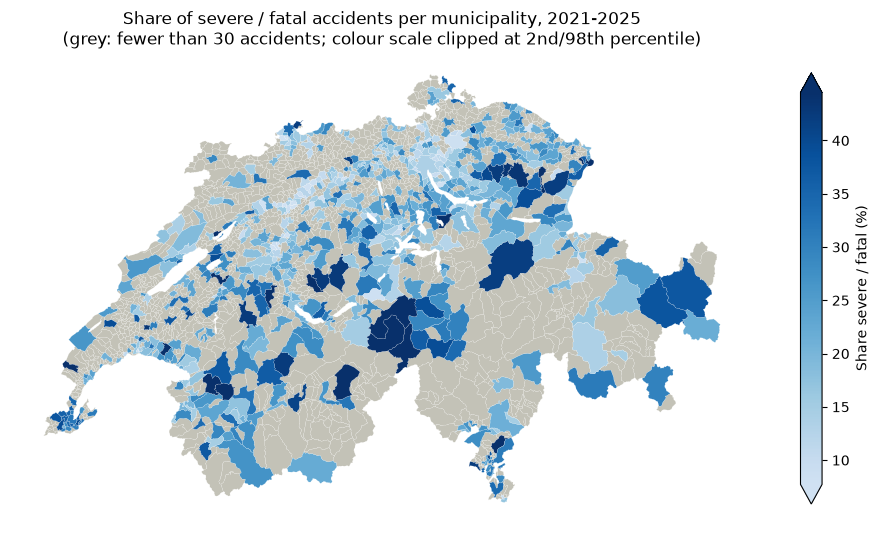

In [26]:
# Blues without the almost-white lower end, so that low values stay visible on white
CMAP_SEQ = mcolors.LinearSegmentedColormap.from_list(
    "blues_trunc", plt.cm.Blues(np.linspace(0.2, 1.0, 256)))


def choropleth(gdf_plot, title, ax, vmin, vmax):
    ok = gdf_plot["cases"] >= MIN_N
    gdf_plot[~ok].plot(ax=ax, color=COLOR_GREY, edgecolor="white", linewidth=0.1)
    gdf_plot[ok].plot(ax=ax, column="share_severe_pct", cmap=CMAP_SEQ, vmin=vmin, vmax=vmax,
                      edgecolor="white", linewidth=0.1, legend=True,
                      legend_kwds={"label": "Share severe / fatal (%)", "shrink": 0.7})
    ax.set_title(title)
    ax.set_axis_off()

ok = gdf_m["cases"] >= MIN_N
vmin, vmax = gdf_m.loc[ok, "share_severe_pct"].quantile([0.02, 0.98])

fig, ax = plt.subplots(figsize=(12, 8))
choropleth(gdf_m, f"Share of severe / fatal accidents per municipality, 2021-2025\n"
                  f"(grey: fewer than {MIN_N} accidents; colour scale clipped at 2nd/98th percentile)",
           ax, vmin, vmax)
plt.show()

Canton level: much larger case numbers per region and therefore more robust shares.

Cantons without match: 0
Smallest canton n: 125


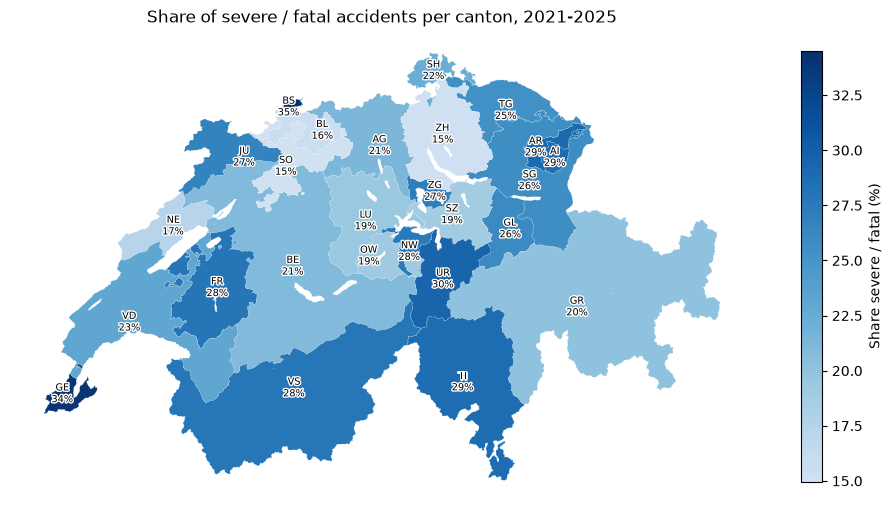

CantonCode,BS,GE,UR,AR,AI,TI,FR,VS,NW,ZG,JU,GL,SG,TG,VD,SH,AG,BE,GR,LU,OW,SZ,NE,BL,ZH,SO
cases,1507.00,5904.00,620.00,522.00,125.0,3278.00,2833.00,3002.00,468.00,1392.00,674.00,444.0,4788.00,2643.00,8501.00,966.00,5515.00,12396.00,2310.00,5075.00,406.00,1395.00,1849.00,2288.0,17135.00,3157.00
severe_cases,520.00,2005.00,183.00,152.00,36.0,941.00,793.00,834.00,129.00,379.00,180.00,115.0,1229.00,671.00,1973.00,216.00,1171.00,2606.00,467.00,988.00,78.00,264.00,321.00,357.0,2610.00,472.00
share_severe_pct,34.51,33.96,29.52,29.12,28.8,28.71,27.99,27.78,27.56,27.23,26.71,25.9,25.67,25.39,23.21,22.36,21.23,21.02,20.22,19.47,19.21,18.92,17.36,15.6,15.23,14.95


In [27]:
gdf_kt = gdf[["KTKZ", "geometry"]].dissolve(by="KTKZ").reset_index()
kt = severe_share_table(df, "CantonCode").reset_index()
gdf_kt = gdf_kt.merge(kt, left_on="KTKZ", right_on="CantonCode", how="left")
print("Cantons without match:", gdf_kt["cases"].isna().sum())
print("Smallest canton n:", int(gdf_kt["cases"].min()))

fig, ax = plt.subplots(figsize=(12, 8))
choropleth(gdf_kt, "Share of severe / fatal accidents per canton, 2021-2025", ax,
           gdf_kt["share_severe_pct"].min(), gdf_kt["share_severe_pct"].max())
for _, r in gdf_kt.iterrows():
    pt = r.geometry.representative_point()
    ax.annotate(f"{r['KTKZ']}\n{r['share_severe_pct']:.0f}%", (pt.x, pt.y),
                ha="center", va="center", fontsize=7,
                path_effects=[pe.withStroke(linewidth=2, foreground="white")])
plt.show()

display(kt.sort_values("share_severe_pct", ascending=False).set_index("CantonCode").T)

**Interpretation:** **CRS check:** The geojson has no `crs` member, and the bounds lie in degrees within Switzerland, so the coordinates are WGS84 (EPSG:4326). They were set explicitly and projected to LV95 (EPSG:2056). All municipality codes from the accident data were found in `GDENR`. **Municipality map:** many municipalities are grey because they have fewer than 30 accidents, and these are mostly small rural and alpine municipalities. The map therefore shows rural areas less completely, exactly the group that matters for H1. The coloured shares vary strongly between neighbouring municipalities, which is partly random noise. **Canton map:** some urban cantons (e.g. Geneva, Basel-Stadt) have high shares, and some other cantons with large cities have low shares. At canton level the simple urban/rural pattern is therefore not visible, which shows that cantonal differences have other sources as well (road network, traffic mix, possibly differences in how injuries are classified, which is not verified). Conclusions about individual accidents cannot be drawn from aggregated maps (ecological fallacy). Regional clustering is one reason for cluster-robust standard errors in the model.

## 8. Summary of the EDA

In [28]:
summary = pd.DataFrame([
    {"test": "H1 3x2 area_type x severe", "n": int(h1_ct.values.sum()),
     "chi2": h1_res["chi2"], "dof": h1_res["dof"], "p_value": h1_res["p"],
     "cramers_v": cramers_v(h1_ct)},
    {"test": "H1 2x2 Rural vs Urban x severe", "n": int(h1_ct2.values.sum()),
     "chi2": h1_res2["chi2"], "dof": h1_res2["dof"], "p_value": h1_res2["p"],
     "cramers_v": cramers_v(h1_ct2)},
    {"test": "H2 2x2 night x severe", "n": int(h2_ct.values.sum()),
     "chi2": h2_res["chi2"], "dof": h2_res["dof"], "p_value": h2_res["p"],
     "cramers_v": cramers_v(h2_ct)},
])
summary["chi2"] = summary["chi2"].round(2)
summary["cramers_v"] = summary["cramers_v"].round(3)
summary["p_value"] = summary["p_value"].map(lambda v: f"{v:.3g}")
display(summary)

effects = pd.concat([
    risk_comparison(df, "area_type", "Rural", "Urban"),
    risk_comparison(df, "day_night", "Night (22-05h)", "Day (06-21h)"),
], ignore_index=True)
display(effects)

,test,n,chi2,dof,p_value,cramers_v
0,H1 3x2 area_type x severe,89193,532.77,2,2.04e-116,0.077
1,H1 2x2 Rural vs Urban x severe,71730,467.28,1,1.25e-103,0.081
2,H2 2x2 night x severe,89193,38.66,1,5.04e-10,0.021


,measure,estimate,ci_lower_95,ci_upper_95
0,Risk difference Rural - Urban (pp),8.511,7.682,9.341
1,Risk ratio Rural / Urban,1.428,1.384,1.473
2,Risk difference Night (22-05h) - Day (06-21h) ...,2.895,1.952,3.838
3,Risk ratio Night (22-05h) / Day (06-21h),1.133,1.090,1.178


**Summary:** In the bivariate analysis both hypotheses are supported in direction: the share of severe/fatal accidents is higher in rural than in urban municipalities (H1) and higher at night than during the day (H2). Both χ² tests are highly significant, but the effect sizes are small; the urban/rural effect is clearly larger than the day/night effect. The combination plot suggests that the night effect differs between area types, and accident type is strongly associated with severity and distributed differently across area types. The next step is the logistic regression in `03_model.ipynb` with `accident_type` and `road_type` as controls, cluster-robust standard errors by municipality and optionally the `rural x night` interaction.

### Limitations

- Only accidents **with personal injury** are recorded; accidents with property damage only are missing. The analysis compares severity *given* an injury accident, not accident risk.
- No exposure data (traffic volume, kilometres driven): more accidents in a region or hour does not mean higher risk.
- Associations only, no causal statements. Differences between groups can be caused by other factors (speed, road type, accident type, alcohol, weather) that are only partly controlled in the model.
- Large n: almost every difference becomes statistically significant, therefore the effect sizes are reported.
- Night is defined by clock time (22:00-05:59), not by actual darkness.
- Accidents within the same municipality are not independent; this is addressed in `03_model.ipynb` with cluster-robust standard errors.

## AI usage log

| Item | Entry |
|---|---|
| Tool | Claude Code (model Claude Opus 5.5) in VS Code |
| Task | Set up the branch `eda`, create this notebook (structure, helper functions for χ² / Cramér's V / risk difference / risk ratio, plots, maps) and draft the interpretations. |
| Example prompt | "Create `02_eda.ipynb`: overview, H1 (area_type x severe) and H2 (night x severe) with crosstabs, bar charts, `chi2_contingency` (χ², dof, p, expected frequencies), Cramér's V, risk difference and risk ratio with 95 % CI, interaction plot, time plot with night window, control variables, map with minimum n per region. Do not hard-code numbers, do not guess codes." |
| What helped | Fast setup of reusable functions (same analysis for H1 and H2), formulas for the effect sizes and confidence intervals, CRS check of the geojson, first drafts of the interpretations. |
| What did not work | (1) The default Python on the laptop was an old Anaconda 3.7 without `pyarrow`/`geopandas`/`folium`, so the parquet could not be read; a new virtual environment with Python 3.13 was needed. (2) The registered Jupyter kernel `python3` and the `jupyter` command still pointed to Anaconda, so the first run failed with `ModuleNotFoundError: geopandas`. (3) First version of the canton map: lowest values almost white (invisible) and labels on dark cantons unreadable; month plot labels overlapped. (4) The AI could not give meanings for `at*`, `rt*`, `aw*` codes, because they are not in the parquet file; they were deliberately not guessed. |
| Own check / correction | Before: plots with overlapping/invisible labels; after: truncated colour scale, outlined labels, case numbers in tables. All interpretations were written only after the code had run and were compared with the printed tables (e.g. the interaction plot shows that the night effect is *not* visible in rural municipalities, which contradicts the simple expectation). Person B must re-read and, where needed, rewrite the interpretations in their own words. |
| What I (person B) can explain | Why χ² is significant but Cramér's V is small (large n); difference between risk difference, risk ratio and odds ratio; why expected frequencies ≥ 5 are checked; why regions with n < 30 are grey; why the maps cannot be used for individual-level conclusions; CRS (WGS84 vs. LV95). |

### Jupyter notebook --footer info--

In [29]:
import os
import platform
import socket
from platform import python_version
from datetime import datetime

print('-----------------------------------')
print(os.name.upper())
print(platform.system(), '|', platform.release())
print('Datetime:', datetime.now().strftime("%Y-%m-%d %H:%M:%S"))
print('Python Version:', python_version())
print('-----------------------------------')

-----------------------------------
NT
Windows | 10
Datetime: 2026-11-14 16:31:47
Python Version: 3.13.17
-----------------------------------
